# Bussiness Problem

- we need to predict whether the customer will churn/exit or not 
- The given data is related to bank and there cutomers 

In [82]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [83]:
pd.set_option("display.max_rows", None)

In [84]:
customers_data = pd.read_csv("../Datasets/Churn_Modelling.csv")
customers_data.head()

,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,3,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,4,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,5,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


**Column Name Meaning**
- RowNumber	= Serial number/index of the row
- CustomerId = Unique ID of each customer
- Surname = Customer’s last name
- CreditScore	= Credit score of the customer
- Geography = Country/location of the customer (France, Germany, Spain, etc.)
- Gender	= Male or Female
- Age	= Age of the customer
- Tenure	= Number of years the customer has stayed with the bank/company
- Balance	= Account balance of the customer
- NumOfProducts	= Number of products/services used by the customer
- HasCrCard	= Whether customer has a credit card (1 = Yes, 0 = No)
- IsActiveMember	= Whether customer is an active member (1 = Active, 0 = Not Active)
- EstimatedSalary	= Estimated yearly salary of customer
- Exited	= Target column → whether customer left/churned (1 = Yes, 0 = No)


# Data Exploration 

In [85]:
customers_data.shape

(10000, 14)

In [86]:
customers_data.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   RowNumber        10000 non-null  int64  
 1   CustomerId       10000 non-null  int64  
 2   Surname          10000 non-null  str    
 3   CreditScore      10000 non-null  int64  
 4   Geography        10000 non-null  str    
 5   Gender           10000 non-null  str    
 6   Age              10000 non-null  int64  
 7   Tenure           10000 non-null  int64  
 8   Balance          10000 non-null  float64
 9   NumOfProducts    10000 non-null  int64  
 10  HasCrCard        10000 non-null  int64  
 11  IsActiveMember   10000 non-null  int64  
 12  EstimatedSalary  10000 non-null  float64
 13  Exited           10000 non-null  int64  
dtypes: float64(2), int64(9), str(3)
memory usage: 1.1 MB


**Observation 1**

- in the table there are 14 columns, and three data types float int and str. as per column name all the columns having correct data type means no wrong data type in this table

**Cleaning Point**
- NA

In [87]:
customers_data.columns.tolist()

['RowNumber',
 'CustomerId',
 'Surname',
 'CreditScore',
 'Geography',
 'Gender',
 'Age',
 'Tenure',
 'Balance',
 'NumOfProducts',
 'HasCrCard',
 'IsActiveMember',
 'EstimatedSalary',
 'Exited']

In [88]:
customers_data.duplicated().sum()

np.int64(0)

**Observation 2**

- there is no duplicate record in this data

**Data Cleaning point 2**

- NA

In [89]:
customers_data.isnull().sum()

RowNumber          0
CustomerId         0
Surname            0
CreditScore        0
Geography          0
Gender             0
Age                0
Tenure             0
Balance            0
NumOfProducts      0
HasCrCard          0
IsActiveMember     0
EstimatedSalary    0
Exited             0
dtype: int64

**Observation 3**

- there is no missing values in this data set 

**Cleaning Point 3**
- NA

In [90]:
customers_data['CustomerId'].unique()

array([15634602, 15647311, 15619304, ..., 15584532, 15682355, 15628319],
      shape=(10000,))

In [91]:
customers_data['RowNumber'].unique()

array([    1,     2,     3, ...,  9998,  9999, 10000], shape=(10000,))

In [92]:
customers_data['Surname'].unique()

<StringArray>
[  'Hargrave',       'Hill',       'Onio',       'Boni',   'Mitchell',
        'Chu',   'Bartlett',     'Obinna',         'He',         'H?',
 ...
 'MacPherson',      'Parks',      'Edith',     'Lajoie',     'Torode',
    'Salinas',  'Cleveland',  'Kashiwagi',   'Aldridge',   'Burbidge']
Length: 2932, dtype: str

In [93]:
customers_data['Gender'].unique()

<StringArray>
['Female', 'Male']
Length: 2, dtype: str

**Observation 4**

- the columns RowNumber, customerID and Surname are contaning all the unique values
- surname have some duplicate recodes but this columns are not taking any logic or not required in modeling 

**Data Cleaning point 4**

- We can remove unwanted column 
- RowNumber
- CustomerID
- Surname

In [94]:
customers_data['Exited'].value_counts()

Exited
0    7963
1    2037
Name: count, dtype: int64

In [95]:
customers_data['Geography'].value_counts()

Geography
France     5014
Germany    2509
Spain      2477
Name: count, dtype: int64

# Data Visualization 

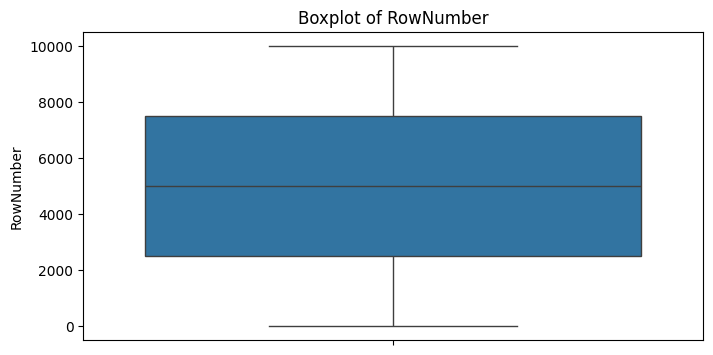

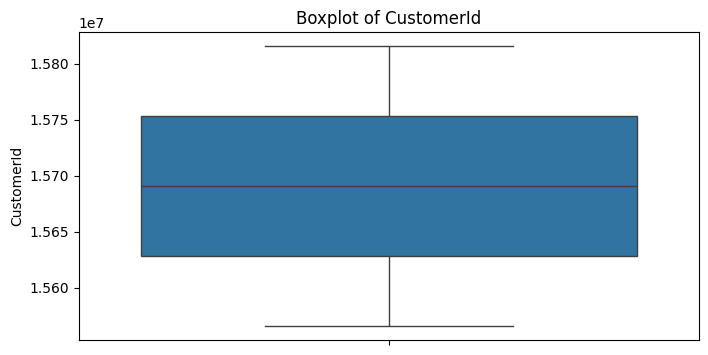

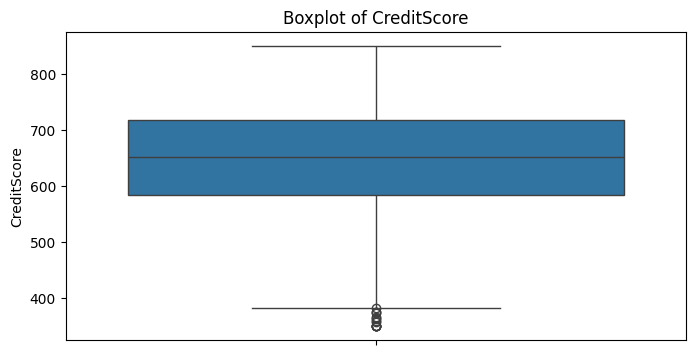

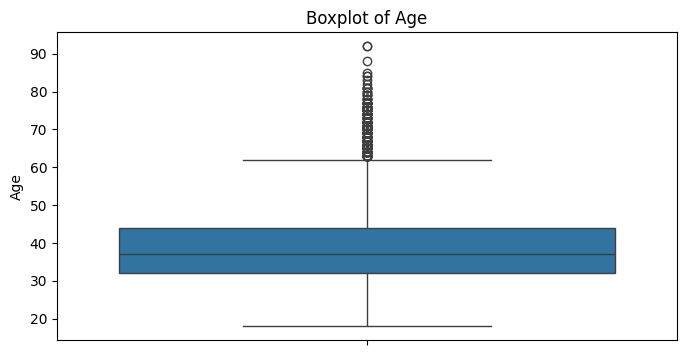

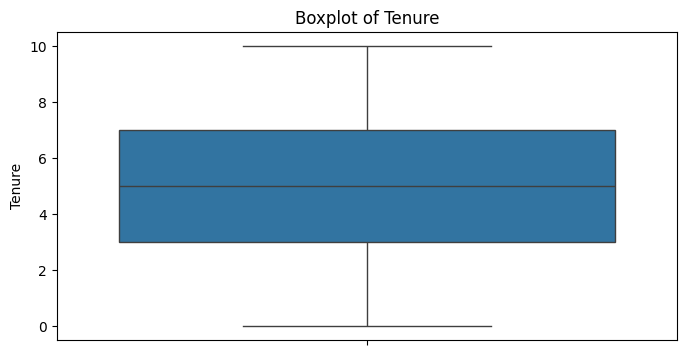

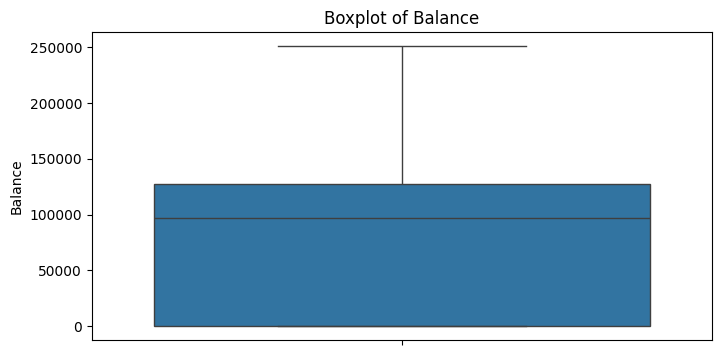

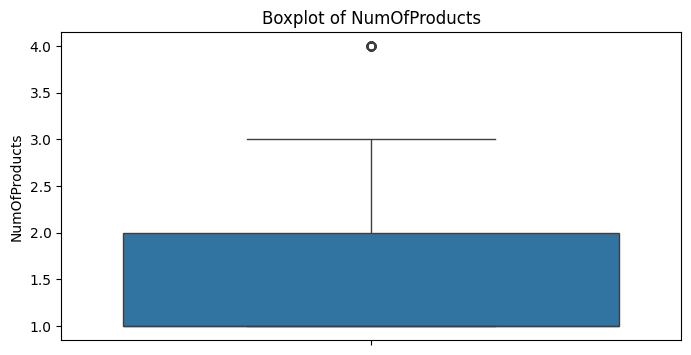

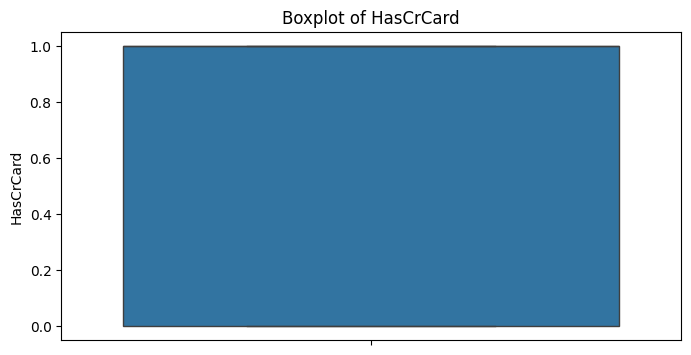

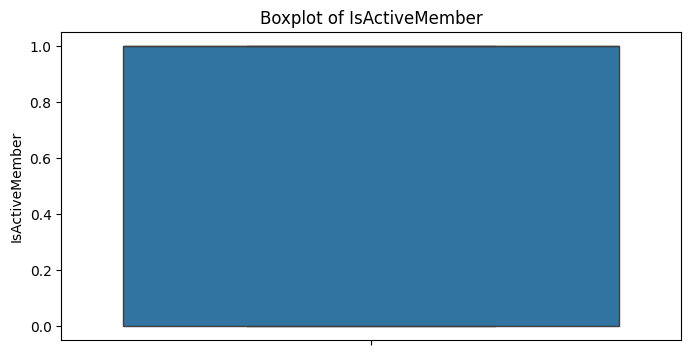

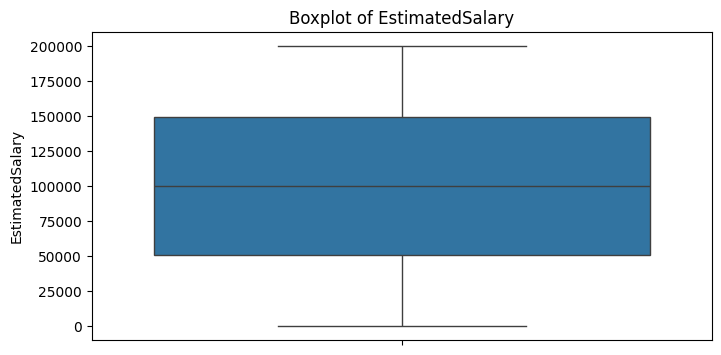

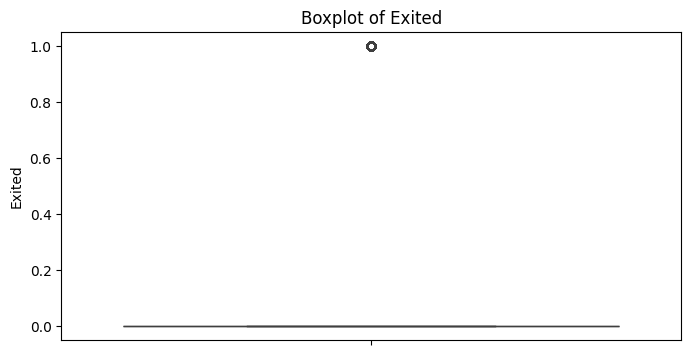

In [96]:
for i in customers_data.select_dtypes(include=['int64', 'float64']).columns:
    plt.figure(figsize=(8, 4))
    sns.boxplot(y=customers_data[i])
    plt.title(f'Boxplot of {i}')
    plt.show()
    

In [97]:
Q1 = customers_data["Age"].quantile(0.25)
Q3 = customers_data["Age"].quantile(0.75)
IQR = Q3 - Q1
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR
customers_data[(customers_data["Age"] < lower_bound) | (customers_data["Age"] > upper_bound)]



,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
58,59,15623944,T'ien,511,Spain,Female,66,4,0.00,1,1,0,1643.11,1
85,86,15805254,Ndukaku,652,Spain,Female,75,10,0.00,2,1,1,114675.75,0
104,105,15804919,Dunbabin,670,Spain,Female,65,1,0.00,1,1,1,177655.68,1
158,159,15589975,Maclean,646,France,Female,73,6,97259.25,1,0,1,104719.66,0
181,182,15789669,Hsia,510,France,Male,65,2,0.00,2,1,1,48071.61,0
230,231,15808473,Ringrose,673,France,Male,72,1,0.00,2,0,1,111981.19,0
234,235,15704769,Smith,585,France,Female,67,5,113978.97,2,0,1,93146.11,0
243,244,15596175,McIntosh,659,Germany,Male,67,6,117411.60,1,1,1,45071.09,1
252,253,15793726,Matveyeva,681,France,Female,79,0,0.00,2,0,1,170968.99,0
310,311,15712287,Pokrovskii,652,France,Female,80,4,0.00,2,1,1,188603.07,0


In [98]:
Q1 = customers_data["CreditScore"].quantile(0.25)
Q3 = customers_data["CreditScore"].quantile(0.75)
IQR = Q3 - Q1
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR
customers_data[(customers_data["CreditScore"] < lower_bound) | (customers_data["CreditScore"] > upper_bound)]



,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
7,8,15656148,Obinna,376,Germany,Female,29,4,115046.74,4,1,0,119346.88,1
942,943,15804586,Lin,376,France,Female,46,6,0.00,1,1,0,157333.69,1
1193,1194,15779947,Thomas,363,Spain,Female,28,6,146098.43,3,1,0,100615.14,1
1405,1406,15612494,Panicucci,359,France,Female,44,6,128747.69,1,1,0,146955.71,1
1631,1632,15685372,Azubuike,350,Spain,Male,54,1,152677.48,1,1,1,191973.49,1
1838,1839,15758813,Campbell,350,Germany,Male,39,0,109733.20,2,0,0,123602.11,1
1962,1963,15692416,Aikenhead,358,Spain,Female,52,8,143542.36,3,1,0,141959.11,1
2473,2474,15679249,Chou,351,Germany,Female,57,4,163146.46,1,1,0,169621.69,1
2579,2580,15597896,Ozoemena,365,Germany,Male,30,0,127760.07,1,1,0,81537.85,1
8154,8155,15791533,Ch'ien,367,Spain,Male,42,6,93608.28,1,1,0,168816.73,1


**Observation 5**

- There are some outliers
- all the outlier points are original values so we are retain it 

**Data Cleaning point 5**

- NA

<Axes: xlabel='Age', ylabel='Count'>

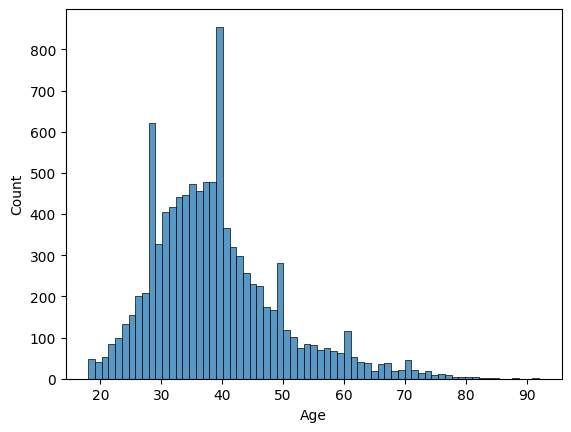

In [99]:

sns.histplot(customers_data['Age'])

# Feature vs Target Analysis

In [100]:
pd.crosstab(customers_data['Geography'], customers_data['Exited'])

Exited,0,1
Geography,,
France,4204,810
Germany,1695,814
Spain,2064,413


<Axes: xlabel='Geography', ylabel='count'>

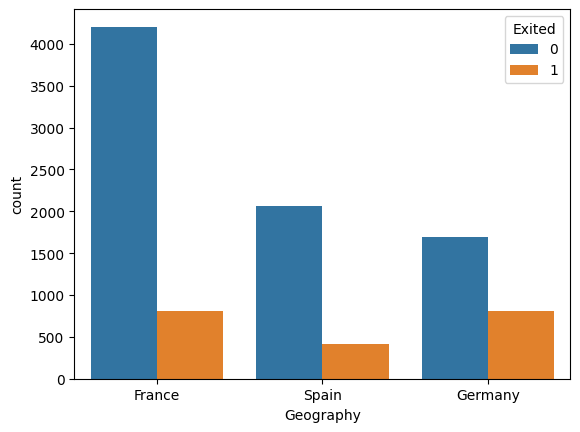

In [101]:
sns.countplot(x='Geography', hue='Exited', data=customers_data)

<Axes: xlabel='Tenure', ylabel='count'>

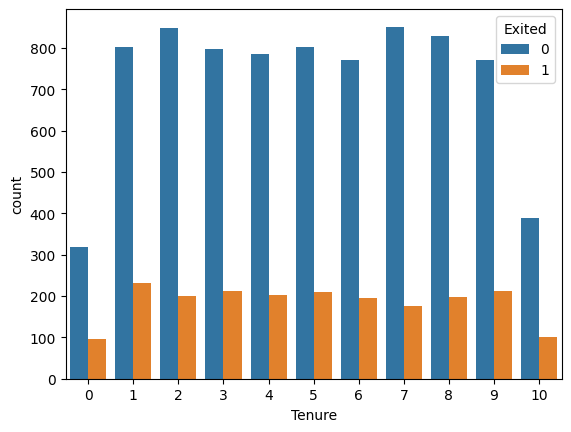

In [102]:
sns.countplot(x='Tenure', hue='Exited', data=customers_data)

In [103]:

pd.crosstab(customers_data['HasCrCard'], customers_data['Exited'])

Exited,0,1
HasCrCard,,
0,2332,613
1,5631,1424


In [104]:

pd.crosstab(customers_data['IsActiveMember'], customers_data['Exited'])

Exited,0,1
IsActiveMember,,
0,3547,1302
1,4416,735


<Axes: xlabel='Gender', ylabel='count'>

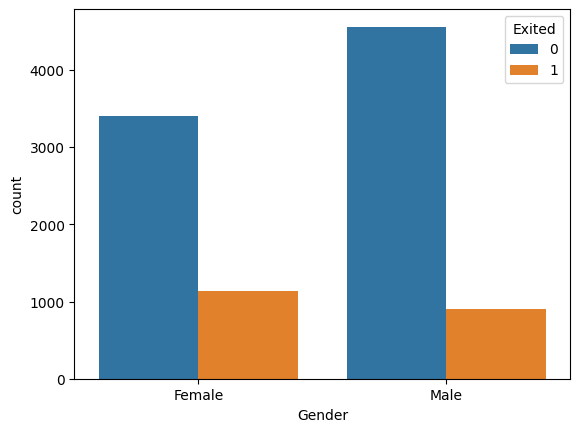

In [105]:
sns.countplot(x='Gender', hue='Exited', data=customers_data)

<Axes: xlabel='Exited', ylabel='Balance'>

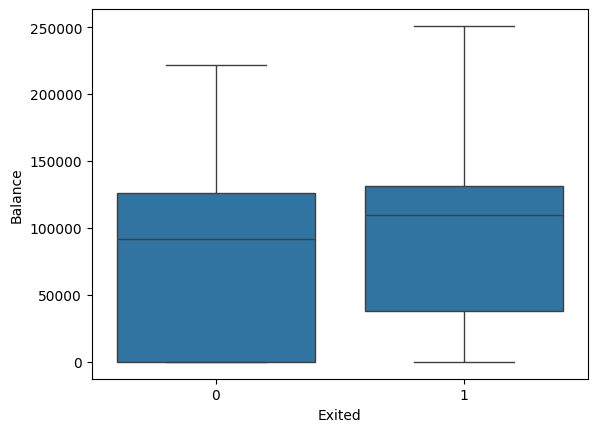

In [106]:
sns.boxplot(x='Exited', y='Balance', data=customers_data)

# Data Cleaning 

- As per Data cleaning point 4 we have some unwanted columns need to drop it

In [107]:
customers_data = customers_data.drop(columns=['RowNumber', 'CustomerId', 'Surname'])

In [108]:
customers_data.head()

,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


# Encoding

- As per bussiness problem and data andastanding we know this is binary classification project
- to apply process on features it should be in numeric data 
- there for we will encode it and use in model 

In [109]:

from sklearn.preprocessing import LabelEncoder
from sklearn.preprocessing import OneHotEncoder

In [111]:
geo = pd.get_dummies(customers_data['Geography'], drop_first=True, dtype=int)

In [113]:
geo.head()

,Germany,Spain
0,0,0
1,0,1
2,0,0
3,0,0
4,0,1


In [114]:
customers_data = pd.concat([customers_data, geo], axis=1)
customers_data.head()

,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited,Germany,Spain
0,619,France,Female,42,2,0.00,1,1,1,101348.88,1,0,0
1,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0,0,1
2,502,France,Female,42,8,159660.80,3,1,0,113931.57,1,0,0
3,699,France,Female,39,1,0.00,2,0,0,93826.63,0,0,0
4,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0,0,1


In [116]:
customers_data = customers_data.drop(columns=['Geography'])

In [ ]:
le = LabelEncoder()
customers_data['Gender'] = le.fit_transform(customers_data['Gender'])
customers_data.head()

,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited,Germany,Spain
0,619,France,0,42,2,0.00,1,1,1,101348.88,1,0,0
1,608,Spain,0,41,1,83807.86,1,0,1,112542.58,0,0,1
2,502,France,0,42,8,159660.80,3,1,0,113931.57,1,0,0
3,699,France,0,39,1,0.00,2,0,0,93826.63,0,0,0
4,850,Spain,0,43,2,125510.82,1,1,1,79084.10,0,0,1


# Final Transformed dataset

In [118]:
customers_data

,CreditScore,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited,Germany,Spain
0,619,0,42,2,0.00,1,1,1,101348.88,1,0,0
1,608,0,41,1,83807.86,1,0,1,112542.58,0,0,1
2,502,0,42,8,159660.80,3,1,0,113931.57,1,0,0
3,699,0,39,1,0.00,2,0,0,93826.63,0,0,0
4,850,0,43,2,125510.82,1,1,1,79084.10,0,0,1
5,645,1,44,8,113755.78,2,1,0,149756.71,1,0,1
6,822,1,50,7,0.00,2,1,1,10062.80,0,0,0
7,376,0,29,4,115046.74,4,1,0,119346.88,1,1,0
8,501,1,44,4,142051.07,2,0,1,74940.50,0,0,0
9,684,1,27,2,134603.88,1,1,1,71725.73,0,0,0


# Saving cleaned data for modeling

In [119]:
customers_data.to_excel("../Datasets/cleaned_customers_churn_data.xlsx", index=False)